In [1]:
# conda env 'vis2'

import sys
sys.path.append('/data/keeling/a/johntl3/b/LundstromPub2025/src')
import visualization as vis

import warnings
warnings.filterwarnings("ignore")


In [2]:
at3d_obs_file = '../../../../intermediate_data/AT3D_OBS_CAMP2Ex_RF17_default_1400.nc'
iter_dir = '../iterations/'
loss_file = '../loss.csv'

### BRF Difference

In [ ]:
# out_dir = './brf_diff_movie/'
# vis.brf_diff_frames(at3d_obs_file, iter_dir, out_dir, 'MISR', s=2, brf_vmin=0, brf_vmax=0.5, diff_range=0.25)
# vis.make_movie(out_dir + 'movie.gif', nframes=None, fps=3, bounce=False)

In [ ]:
from util import load_sensor_dict
import glob
import numpy as np
import at3d
import matplotlib.pyplot as plt
import os

vmin=0.0
vmax=0.4

iter_files = np.sort(glob.glob(iter_dir + 'iter*.nc'))

out_dir = './obs_static/'
os.makedirs(out_dir, exist_ok=True)
plt.style.use('seaborn-v0_8-talk')
f, ax = plt.subplots(1, 9, figsize=(15, 2))
vis.plot_measurements(at3d_obs_file, 'MISR', f, ax, vmin=vmin, vmax=vmax, set_title=False)
titles = ['+70.5', '+60.0', '+45.6', '+26.1', '0', '-26.1', '-45.6', '-60.0', '-70.5']
for i, a in enumerate(ax):
    a.set_xticks([])
    a.set_yticks([])
    a.set_title(titles[i])
plt.subplots_adjust(wspace=0, hspace=0)
f.savefig(out_dir+'obs.png', dpi=300, bbox_inches='tight')

out_dir = './forward_sim/'
os.makedirs(out_dir, exist_ok=True)
plt.style.use('seaborn-v0_8-talk')
for i in range(len(iter_files)):
    f, ax = plt.subplots(1, 9, figsize=(15, 2))
    vis.plot_measurements(iter_files[i], 'MISR', f, ax, vmin=vmin, vmax=vmax, set_title=False)
    titles = ['+70.5', '+60.0', '+45.6', '+26.1', '0', '-26.1', '-45.6', '-60.0', '-70.5']
    for j, a in enumerate(ax):
        a.set_xticks([])
        a.set_yticks([])
        a.set_title(titles[j])
    plt.subplots_adjust(wspace=0, hspace=0)
    f.savefig(out_dir+'iter{:03d}.png'.format(i), dpi=300, bbox_inches='tight')
    plt.close(f)

### Optical Depth

In [ ]:
out_dir = './optical_depth_movie/'
vis.optical_depth_frames(iter_dir, out_dir, vmin=0.1, vmax=20, log=True)
vis.make_movie(out_dir + 'movie.gif', nframes=None, fps=3, bounce=False)

### Extinction Cross Section

In [ ]:
x = 3.3
x_str = '{:.2f}'.format(x).replace('.','p')
out_dir = './extinction_cs_x_{}_log_movie/'.format(x_str)
vis.extinction_cross_section_frames(iter_dir, out_dir, dim='x', loc=x, vmin=0.1, vmax=25, log=True)
vis.make_movie(out_dir + 'movie.gif', nframes=None, fps=3, bounce=False)

### 3D extinction

In [ ]:
out_dir = './extinction3D_notitle_movie_03/'
vis.extinction3D_frames(
    iter_dir,
    out_dir,
    title=False,
    frames='all',
    vmin=0,
    vmax=37.5,
    opacity=0.1,
    sfc_cnt=17,
    theta=35,
    phi=5.4,
    r=2.5
)
vis.make_movie(out_dir + 'movie.gif', nframes=None, fps=3, bounce=False)

In [ ]:
import glob
import plotly.graph_objects as go
import os
import numpy as np
import at3d

out_dir = './extinction_flyover_02/'
os.makedirs(out_dir, exist_ok=True)

iter_files = np.sort(glob.glob(iter_dir + 'iter*.nc'))
sensors, solvers, rte_grid = at3d.util.load_forward_model(iter_files[-1])

cloud = solvers[0.67].medium['cloud']
X, Y, Z = np.meshgrid(cloud.x.data, cloud.y.data, cloud.z.data, indexing='ij')
data = go.Volume(x=X.flatten(), y=Y.flatten(), z=Z.flatten(), 
                    value=cloud.extinction.data.flatten(), isomin=0, isomax=37.5, 
                    opacity=0.1, surface_count=17, showscale=False)
layout = go.Layout(autosize=False, width=750, height=650)
fig = go.Figure(data=data, layout=layout)
pad = {'b':0, 'l':0, 'r':0, 't':0, 'pad':0}
font = {'size':18}
scene = dict(
    xaxis=dict(title='x (km)', tickvals=[0, 17.6], range=[-1, 18.6]),
    yaxis=dict(title='y (km)', tickvals=[0, 17.6], range=[-1, 18.6]),
    zaxis=dict(title='z (km)', tickvals=[0, 1.4], range=[-0.1, 1.5]),
)

theta = np.radians(35)
phis = np.linspace(0, 2*np.pi, 100)
r = 2.5
h = r * np.sin(theta)

for i, phi in enumerate(phis):
    camera = dict(
        up=dict(x=0, y=0, z=1.0),
        center=dict(x=0.0, y=0.0, z=0.0),
        eye=dict(x=h*np.cos(phi), y=h*np.sin(phi), z=r*np.cos(theta))
    )
    fig.update_layout(scene_camera=camera, margin=pad, font=font, scene=scene)
    fig.write_image('{}iter{:03d}.png'.format(out_dir, i))

spr = 10
n_frames = len(phis)
fps = int(n_frames/spr)
vis.make_movie(out_dir + 'movie.gif', nframes=None, fps=fps, bounce=False)

In [ ]:
spr = 7.5
n_frames = len(phis)
fps = int(n_frames/spr)
vis.make_movie(out_dir + 'movie.gif', nframes=None, fps=fps, bounce=False)

### Objective function

In [ ]:
## Objective function timing

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

loss = pd.read_csv(loss_file)

f, ax = plt.subplots(1, 1, figsize=(8, 5))
ax.plot(np.diff(loss[' total_obj_fn_time']/60), marker='o')
ax.set_xlabel('Iteration')
ax.set_ylabel('Objective Function Time (mins)')
ax.set_xticks(np.arange(0, 19, 2))
ax.grid()

In [ ]:
## Objective function chi**2

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

out_dir = './chi2_movie/'
os.makedirs(out_dir, exist_ok=True)

loss = pd.read_csv(loss_file)
chi2 = loss[1:][' loss'].to_numpy().astype(float)

plt.style.use('seaborn-v0_8-talk')
for i in range(len(chi2)+1):
    f, ax = plt.subplots(1, 1, figsize=(6, 4))
    ax.plot(chi2[:i], marker='o')
    ax.set_xlabel('Iteration')
    ax.set_ylabel(r'$\chi^2$')
    ax.set_ylim([0, 140])
    ax.set_xlim([-1, 19])
    ax.set_xticks(np.arange(0, 19, 2))
    ax.grid()
    f.savefig(out_dir+'iter{:03d}.png'.format(i), bbox_inches='tight')
    plt.close(f)

### 1D Tau

In [3]:
from util import load_sensor_dict
import numpy as np
import glob
import at3d
from scipy.interpolate import griddata
import matplotlib.pyplot as plt

# 1D tau vs AT3D tau
tau1D_file = '../../../../intermediate_data/AT3D_1DTAU_CAMP2Ex_RF17_default_1400.nc'

iter_files = np.sort(glob.glob(iter_dir + 'iter*.nc'))
sensors, solvers, rte_grid = at3d.util.load_forward_model(iter_files[-1])

cloud_3D = solvers[0.67].medium['cloud']

obs = load_sensor_dict(tau1D_file)
cloud_1D = obs['MISR']['sensor_list'][4]

x_1D = cloud_1D.ray_x.data
y_1D = cloud_1D.ray_y.data
tau_1D = cloud_1D.tau.data

x_3D = cloud_3D.x.data
y_3D = cloud_3D.y.data

grid_x, grid_y = np.meshgrid(x_3D, y_3D, indexing='ij')
tau_1D_interpolated = griddata((x_1D, y_1D), tau_1D, (grid_x, grid_y), method='linear')
I_interp = griddata((x_1D, y_1D), cloud_1D.I.data*np.pi/cloud_1D.mu0.data, (grid_x, grid_y), method='linear')

cloud_3D['tau_3D'] = cloud_3D.extinction.integrate('z')
cloud_3D['tau_1D_interp'] = (['x', 'y'], tau_1D_interpolated)
cloud_3D['I'] = (['x', 'y'], I_interp)

Text(0.5, 1.0, 'Difference\nAT3D - 1D')

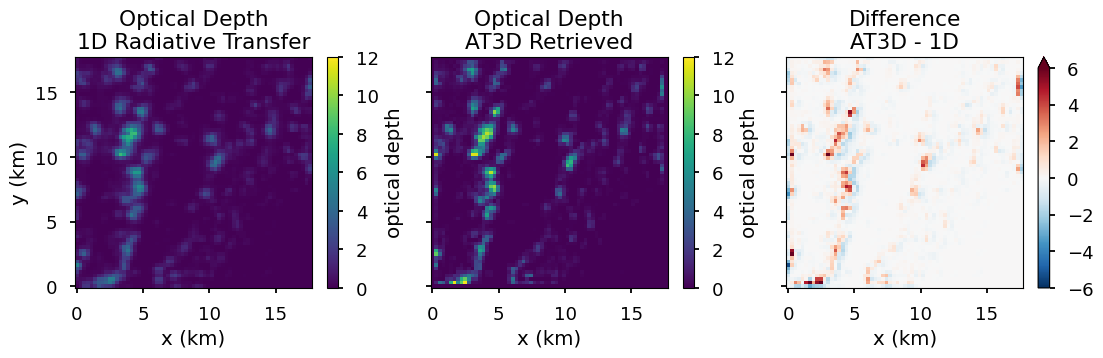

In [4]:
import matplotlib.colors as colors
vmin = 0
vmax = 12
vrange = 6
plt.style.use('seaborn-v0_8-talk')
f, ax = plt.subplots(1, 3, figsize=(13,3), sharex=True, sharey=True)
cloud_3D.tau_1D_interp.plot(ax=ax[0], y='y', vmin=vmin, vmax=vmax, cbar_kwargs={'label': 'optical depth'})
cloud_3D.tau_3D.plot(ax=ax[1], y='y', vmin=vmin, vmax=vmax, cbar_kwargs={'label': 'optical depth'})
# cloud_3D.tau_1D_interp.plot(ax=ax[0], y='y', cbar_kwargs={'label': 'optical depth'}, norm=colors.LogNorm(vmin=0.1, vmax=vmax))
# cloud_3D.tau_3D.plot(ax=ax[1], y='y', cbar_kwargs={'label': 'optical depth'}, norm=colors.LogNorm(vmin=0.1, vmax=vmax))
(cloud_3D.tau_3D - cloud_3D.tau_1D_interp).plot(ax=ax[2], y='y', vmin=-vrange, vmax=vrange, cmap='RdBu_r')
ax[0].set_ylabel('y (km)')
ax[0].set_xlabel('x (km)')
ax[0].set_title('Optical Depth\n1D Radiative Transfer')
ax[1].set_ylabel('')
ax[1].set_xlabel('x (km)')
ax[1].set_title('Optical Depth\nAT3D Retrieved')
ax[2].set_ylabel('')
ax[2].set_xlabel('x (km)')
ax[2].set_title('Difference\nAT3D - 1D')


In [18]:
# import matplotlib.colors as colors
# vmin = 0
# vmax = 12
# vrange = -6
# plt.style.use('seaborn-v0_8-talk')
# f, ax = plt.subplots(1, 3, figsize=(13,3), sharex=True, sharey=True)
# cloud_3D.tau_1D_interp.plot(ax=ax[0], y='y', vmin=vmin, vmax=vmax, cbar_kwargs={'label': 'optical depth'})
# cloud_3D.tau_3D.plot(ax=ax[1], y='y', vmin=vmin, vmax=vmax, cbar_kwargs={'label': 'optical depth'})
# cond = cloud_3D.I.data > 0.04
# (cond*(cloud_3D.tau_3D - cloud_3D.tau_1D_interp)/cloud_3D.tau_3D).plot(ax=ax[2], y='y', vmin=-vrange, vmax=vrange, cmap='RdBu_r')
# ax[0].set_ylabel('y (km)')
# ax[0].set_xlabel('x (km)')
# ax[0].set_title('Optical Depth\n1D Radiative Transfer')
# ax[1].set_ylabel('')
# ax[1].set_xlabel('x (km)')
# ax[1].set_title('Optical Depth\nAT3D Retrieved')
# ax[2].set_ylabel('')
# ax[2].set_xlabel('x (km)')
# ax[2].set_title('Difference\nAT3D - 1D')


Cloud mean tau1d: 0.598
CLoud mean tau3d: 0.640
0.06588471389481375


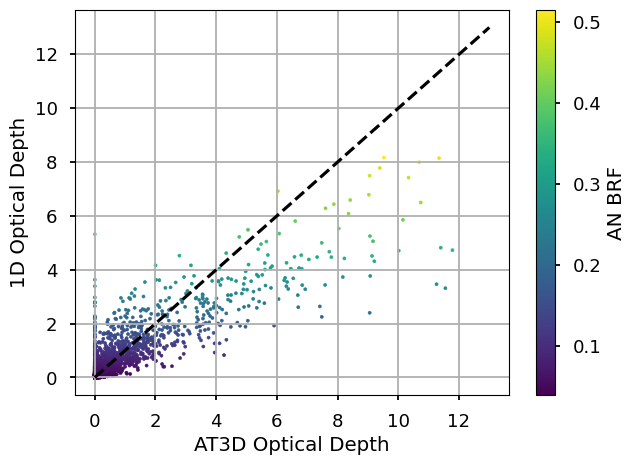

In [17]:
# cond = cloud_3D.tau_3D.data > 0
cond = cloud_3D.I.data > 0.04
plt.style.use('seaborn-v0_8-talk')
f, ax = plt.subplots(1, 1, figsize=(7,5))
s = ax.scatter(cloud_3D.tau_3D.data[cond], cloud_3D.tau_1D_interp.data[cond], c=cloud_3D.I.data[cond], s=5)
plt.colorbar(s, label='AN BRF')
ax.plot([0,13], [0,13], 'k', linestyle='--')
ax.set_xlabel('AT3D Optical Depth')
ax.set_ylabel('1D Optical Depth')
ax.grid()

mean_tau1d = np.mean(cloud_3D.tau_1D_interp.data[cond])
mean_tau3d = np.mean(cloud_3D.tau_3D.data[cond])
print('Cloud mean tau1d: {:.3f}'.format(mean_tau1d))
print('CLoud mean tau3d: {:.3f}'.format(mean_tau3d))
print((mean_tau3d - mean_tau1d) / mean_tau3d)

In [6]:
def rmse(x_r, x_t):
    return 100 * (np.sum((x_r - x_t)**2))**0.5 / (np.sum(x_t)**2)**0.5

def bias(x_r, x_t):
    return 100 * (np.sum(np.abs(x_r)) - np.sum(np.abs(x_t))) / (np.sum(np.abs(x_t)))

Text(0.5, 1.0, '1D vs 3D optical depth\nCloud Volume Constrained')

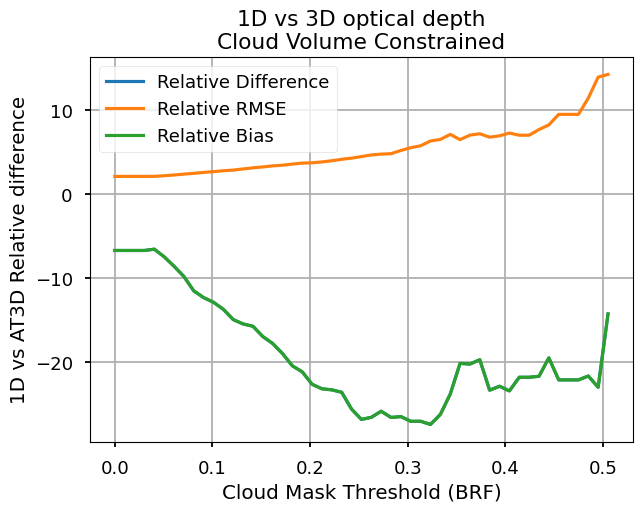

In [7]:
ths = np.linspace(0, 1.0, 100)
rel_diff = np.zeros(ths.shape)
rel_rmse = np.zeros(ths.shape)
rel_bias = np.zeros(ths.shape)
for i, th in enumerate(ths):
    # cond = cloud_3D.tau_3D.data > th
    cond = cloud_3D.I.data > th
    tau1d = cloud_3D.tau_1D_interp.data[cond]
    tau3d = cloud_3D.tau_3D.data[cond]
    mean_tau1d = np.mean(tau1d)
    mean_tau3d = np.mean(tau3d)
    rel_diff[i] = 100 * (mean_tau1d - mean_tau3d) / mean_tau3d
    rel_rmse[i] = rmse(tau1d, tau3d)
    rel_bias[i] = bias(tau1d, tau3d)
f, ax = plt.subplots(1, 1, figsize=(7, 5))
ax.plot(ths, rel_diff, label='Relative Difference')
ax.plot(ths, rel_rmse, label='Relative RMSE')
ax.plot(ths, rel_bias, label='Relative Bias')
ax.set_xlabel('Cloud Mask Threshold (BRF)')
ax.set_ylabel('1D vs AT3D Relative difference')
ax.grid()
ax.legend()
# ax.set_ylim([0, 0.33])
ax.set_title('1D vs 3D optical depth\nCloud Volume Constrained')
# ax.vlines(0.04, 0, 0.6, 'k')